# UIUC airfoil geometry: four dimension reductions

Download and structure the [UIUC coordinate archive](https://m-selig.ae.illinois.edu/ads/coord_database.html), reduce normalized **geometry** to two dimensions with PCA, UMAP, Isomap, and diffusion maps, and colour the points by aerodynamic performance. Interpretation is left to the reader.

Performance is **predicted by NeuralFoil**, not measured UIUC polar data. All airfoils use the same operating conditions. Performance is never an input to the reductions.

Run from the repository root or `notebooks/`, with the project's analysis environment. Install the two additional method packages in the notebook kernel if needed:

In [3]:
# Run once if needed, then restart the kernel:
%pip install umap-learn pydiffmap

  Using cached umap_learn-0.5.12-py3-none-any.whl.metadata (24 kB)
  Using cached pydiffmap-0.2.0.1-py2.py3-none-any.whl.metadata (3.9 kB)
  Using cached numba-0.68.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (2.8 kB)
  Using cached pynndescent-0.6.0-py3-none-any.whl.metadata (6.9 kB)
  Using cached numexpr-2.14.2-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.0 kB)
  Using cached llvmlite-0.50.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (5.1 kB)
Using cached umap_learn-0.5.12-py3-none-any.whl (91 kB)
Using cached pydiffmap-0.2.0.1-py2.py3-none-any.whl (14 kB)
Using cached numba-0.68.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (3.8 MB)
Using cached pynndescent-0.6.0-py3-none-any.whl (73 kB)
Using cached numexpr-2.14.2-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (448 kB)
Using cached llvmlite-0.50.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (59.7 MB)

[notic

In [5]:
import hashlib
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import aerosandbox as asb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pydiffmap.diffusion_map import DiffusionMap
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap
from sklearn.neighbors import kneighbors_graph
from umap import UMAP

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "uiuc_dimension_reduction"
DATA.mkdir(parents=True, exist_ok=True)

SEED = 42
POINTS_PER_SIDE = 100
NEIGHBORS = 30
MAX_AIRFOILS = None  # Set to e.g. 200 for a quicker, seeded subset.
ALPHA = 4.0  # degrees
REYNOLDS = 1e6
MACH = 0.0
N_CRIT = 9.0
MODEL_SIZE = "large"

np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": False})

## 1. Download and structure

Keep the downloaded ZIP and its original `.dat` files. The SHA-256 digest identifies the archive used. The archive is already in Selig contour order: upper trailing edge → leading edge → lower trailing edge.

In [6]:
URL = "https://m-selig.ae.illinois.edu/ads/archives/coord_seligFmt.zip"
archive = DATA / "coord_seligFmt.zip"
if not archive.exists():
    with urlopen(URL, timeout=60) as response:
        payload = response.read()
    archive.write_bytes(payload)

raw_dir = DATA / "raw"
raw_dir.mkdir(exist_ok=True)
with ZipFile(archive) as z:
    members = sorted(name for name in z.namelist() if name.lower().endswith(".dat"))
    filenames = [Path(name).name for name in members]
    if len(set(filenames)) != len(filenames):
        raise ValueError("Archive contains duplicate airfoil filenames.")
    for member, filename in zip(members, filenames):
        target = raw_dir / filename
        if not target.exists():
            target.write_bytes(z.read(member))

files = [raw_dir / name for name in filenames]
if MAX_AIRFOILS is not None and MAX_AIRFOILS < len(files):
    selection = np.random.default_rng(SEED).choice(len(files), MAX_AIRFOILS, replace=False)
    files = [files[i] for i in sorted(selection)]
print(f"Archive: {len(members)} airfoils; selected: {len(files)}")

Archive: 1665 airfoils; selected: 1665


Normalize with AeroSandbox (unit chord, leading edge at the origin, trailing-edge midpoint on the x axis), then repanel to an equal number of cosine-spaced **surface arc-length** positions on each side. Each feature row contains the flattened `(x/c, y/c)` contour, in identical order. These are contour positions, not a shared x grid. Coordinates retain their chord units; no per-feature variance scaling is applied.

Consecutive duplicate points are removed before repaneling. Unreadable or invalid geometries are recorded in `rejected_geometry.csv`.

Geometry matrix: (1660, 398); rejected: 5


,airfoil,reason
0,30p-30n-flap,Nonfinite or nonpositive-area normalized contour.
1,30p-30n-main,Nonfinite or nonpositive-area normalized contour.
2,30p-30n-slat,Nonfinite or nonpositive-area normalized contour.
3,30p-30n,Nonfinite or nonpositive-area normalized contour.
4,naca1,`x` must contain at least 2 elements.


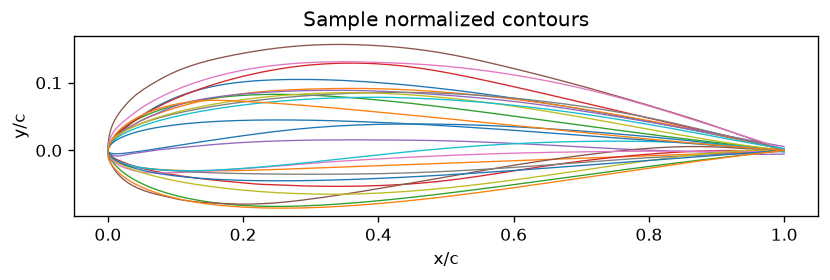

In [7]:
names, contours, airfoils, rejected = [], [], [], []
for path in files:
    try:
        foil = asb.Airfoil(name=path.stem, coordinates=str(path))
        xy = np.asarray(foil.coordinates, dtype=float)
        if xy.ndim != 2 or xy.shape[1] != 2 or len(xy) < 5 or not np.isfinite(xy).all():
            raise ValueError("Expected at least five finite coordinate pairs.")
        xy = xy[np.r_[True, np.any(np.diff(xy, axis=0) != 0, axis=1)]]
        foil = asb.Airfoil(name=path.stem, coordinates=xy).normalize().repanel(
            n_points_per_side=POINTS_PER_SIDE
        )
        if not np.isfinite(foil.coordinates).all() or foil.area() <= 0:
            raise ValueError("Nonfinite or nonpositive-area normalized contour.")
    except (ValueError, UnicodeError, IndexError) as error:
        rejected.append({"airfoil": path.stem, "reason": str(error)})
        continue
    names.append(path.stem)
    contours.append(foil.coordinates)
    airfoils.append(foil)

contours = np.stack(contours)
X = contours.reshape(len(contours), -1)
X = X - X.mean(axis=0)
if len(X) <= NEIGHBORS or NEIGHBORS < 3:
    raise ValueError("Require at least 3 neighbors and more airfoils than neighbors.")
rejected_geometry = pd.DataFrame(rejected, columns=["airfoil", "reason"])
rejected_geometry.to_csv(DATA / "rejected_geometry.csv", index=False)
np.savez_compressed(DATA / "geometry.npz", names=np.array(names), contours=contours, X=X)
print(f"Geometry matrix: {X.shape}; rejected: {len(rejected_geometry)}")
display(rejected_geometry)

fig, ax = plt.subplots(figsize=(8, 3))
for i in np.linspace(0, len(contours) - 1, 12, dtype=int):
    ax.plot(*contours[i].T, lw=0.8, label=names[i])
ax.set(xlabel="x/c", ylabel="y/c", title="Sample normalized contours", aspect="equal")
plt.show()

## 2. Aerodynamic colour values

One fixed operating point: `ALPHA`, `REYNOLDS`, `MACH`, and `N_CRIT` above; free transition (`xtr_upper = xtr_lower = 1`). Use AeroSandbox's existing NeuralFoil interface. Store lift, drag, signed lift-to-drag ratio, and model confidence. Failed evaluations remain NaN and are plotted in grey; no confidence threshold is used to remove points.

In [9]:
rows = []
for name, foil in zip(names, airfoils):
    row = {"airfoil": name, "CL": np.nan, "CD": np.nan,
           "CL/CD": np.nan, "confidence": np.nan, "error": ""}
    try:
        aero = foil.get_aero_from_neuralfoil(
            alpha=ALPHA, Re=REYNOLDS, mach=MACH, n_crit=N_CRIT,
            xtr_upper=1.0, xtr_lower=1.0, model_size=MODEL_SIZE,
        )
        cl = float(np.asarray(aero["CL"]).item())
        cd = float(np.asarray(aero["CD"]).item())
        if not np.isfinite([cl, cd]).all() or cd <= 0:
            raise ValueError("Nonfinite coefficients or nonpositive drag.")
        row.update({"CL": cl, "CD": cd, "CL/CD": cl / cd,
                    "confidence": float(np.asarray(aero["analysis_confidence"]).item())})
    except (ValueError, RuntimeError, np.linalg.LinAlgError) as error:
        row["error"] = str(error)
    rows.append(row)
performance = pd.DataFrame(rows).set_index("airfoil")
performance.to_csv(DATA / "performance.csv")
display(performance.describe())
display(performance.loc[performance["error"] != "", ["error"]])

,CL,CD,CL/CD,confidence
count,1660.000000,1660.000000,1660.000000,1.660000e+03
mean,0.806867,0.008512,98.930979,9.334332e-01
std,0.255271,0.003839,30.147286,1.064778e-01
min,0.085825,0.005503,1.059103,4.288072e-10
25%,0.613952,0.007139,74.497174,9.406145e-01
50%,0.807156,0.007789,100.858628,9.548041e-01
75%,0.961446,0.008920,120.578058,9.642896e-01
max,2.278031,0.088824,197.083026,9.953609e-01


,error
airfoil,


## 3. Four reductions on the same geometry matrix

Use existing implementations: [scikit-learn PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html), [scikit-learn Isomap](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.Isomap.html), and [pyDiffMap](https://pydiffmap.readthedocs.io/en/master/_modules/pydiffmap/diffusion_map.html).

All outputs have two coordinates. PCA uses full SVD. UMAP uses Euclidean distance, `min_dist=0.1`, and a fixed seed. Isomap uses the Euclidean nearest-neighbour graph. Diffusion maps use a Gaussian kernel, a geometry-derived bandwidth (`median` squared pairwise distance divided by 4), and density normalization exponent 0.5. pyDiffMap counts the point itself among its `k` neighbors; use `NEIGHBORS + 1`. The kernel is `exp(-distance² / (4ε))`; this bandwidth gives the median pairwise squared distance an exponent of −1. Its returned coordinates use the library's generator-eigenvalue scaling, rather than a specified finite diffusion time.

The graph component counts below are numerical checks for the chosen neighborhood size. Warnings from the implementations are retained.

In [15]:
graph = kneighbors_graph(X, n_neighbors=NEIGHBORS, mode="connectivity")
print("Geometry neighbor-graph components:", connected_components(graph, directed=False)[0])

diffusion_epsilon = float(np.median(pdist(X, metric="sqeuclidean")) / 4)
models = {
    "PCA": PCA(n_components=2, svd_solver="full"),
    "UMAP": UMAP(n_components=2, n_neighbors=NEIGHBORS, min_dist=0.1,
                 metric="euclidean", random_state=SEED, n_jobs=1),
    "Isomap": Isomap(n_components=2, n_neighbors=NEIGHBORS, eigen_solver="arpack"),
    "Diffusion maps": DiffusionMap.from_sklearn(
        n_evecs=2, k=NEIGHBORS + 1, alpha=1, epsilon=diffusion_epsilon, metric="euclidean"
    ),
}
embeddings = {}
for name, model in models.items():
    embedding = model.fit_transform(X)
    if embedding.shape != (len(names), 2) or not np.isfinite(embedding).all():
        raise ValueError(f"Invalid embedding from {name}.")
    embeddings[name] = embedding
    print(f"{name}: {embedding.shape}")

print("PCA explained variance ratios:", models["PCA"].explained_variance_ratio_)
print("Diffusion kernel components:", connected_components(
    models["Diffusion maps"].kernel_matrix, directed=False
)[0])
print("Diffusion fitted bandwidth:", models["Diffusion maps"].epsilon_fitted)

coordinates = pd.DataFrame({"airfoil": names}).set_index("airfoil")
for name, embedding in embeddings.items():
    coordinates[f"{name}_1"] = embedding[:, 0]
    coordinates[f"{name}_2"] = embedding[:, 1]
coordinates.join(performance).to_csv(DATA / "embeddings_and_performance.csv")

Geometry neighbor-graph components: 1
PCA: (1660, 2)
UMAP: (1660, 2)
Isomap: (1660, 2)
Diffusion maps: (1660, 2)
PCA explained variance ratios: [0.49939142 0.39960135]
Diffusion kernel components: 1
Diffusion fitted bandwidth: 0.026202610464653255


## 4. Performance-coloured views

Each row is one method; each column is one predicted coefficient or ratio. All methods share the same colour limits within a column, using the complete finite range without clipping. Grey points have missing predictions. Embedding axis scales are method-specific.

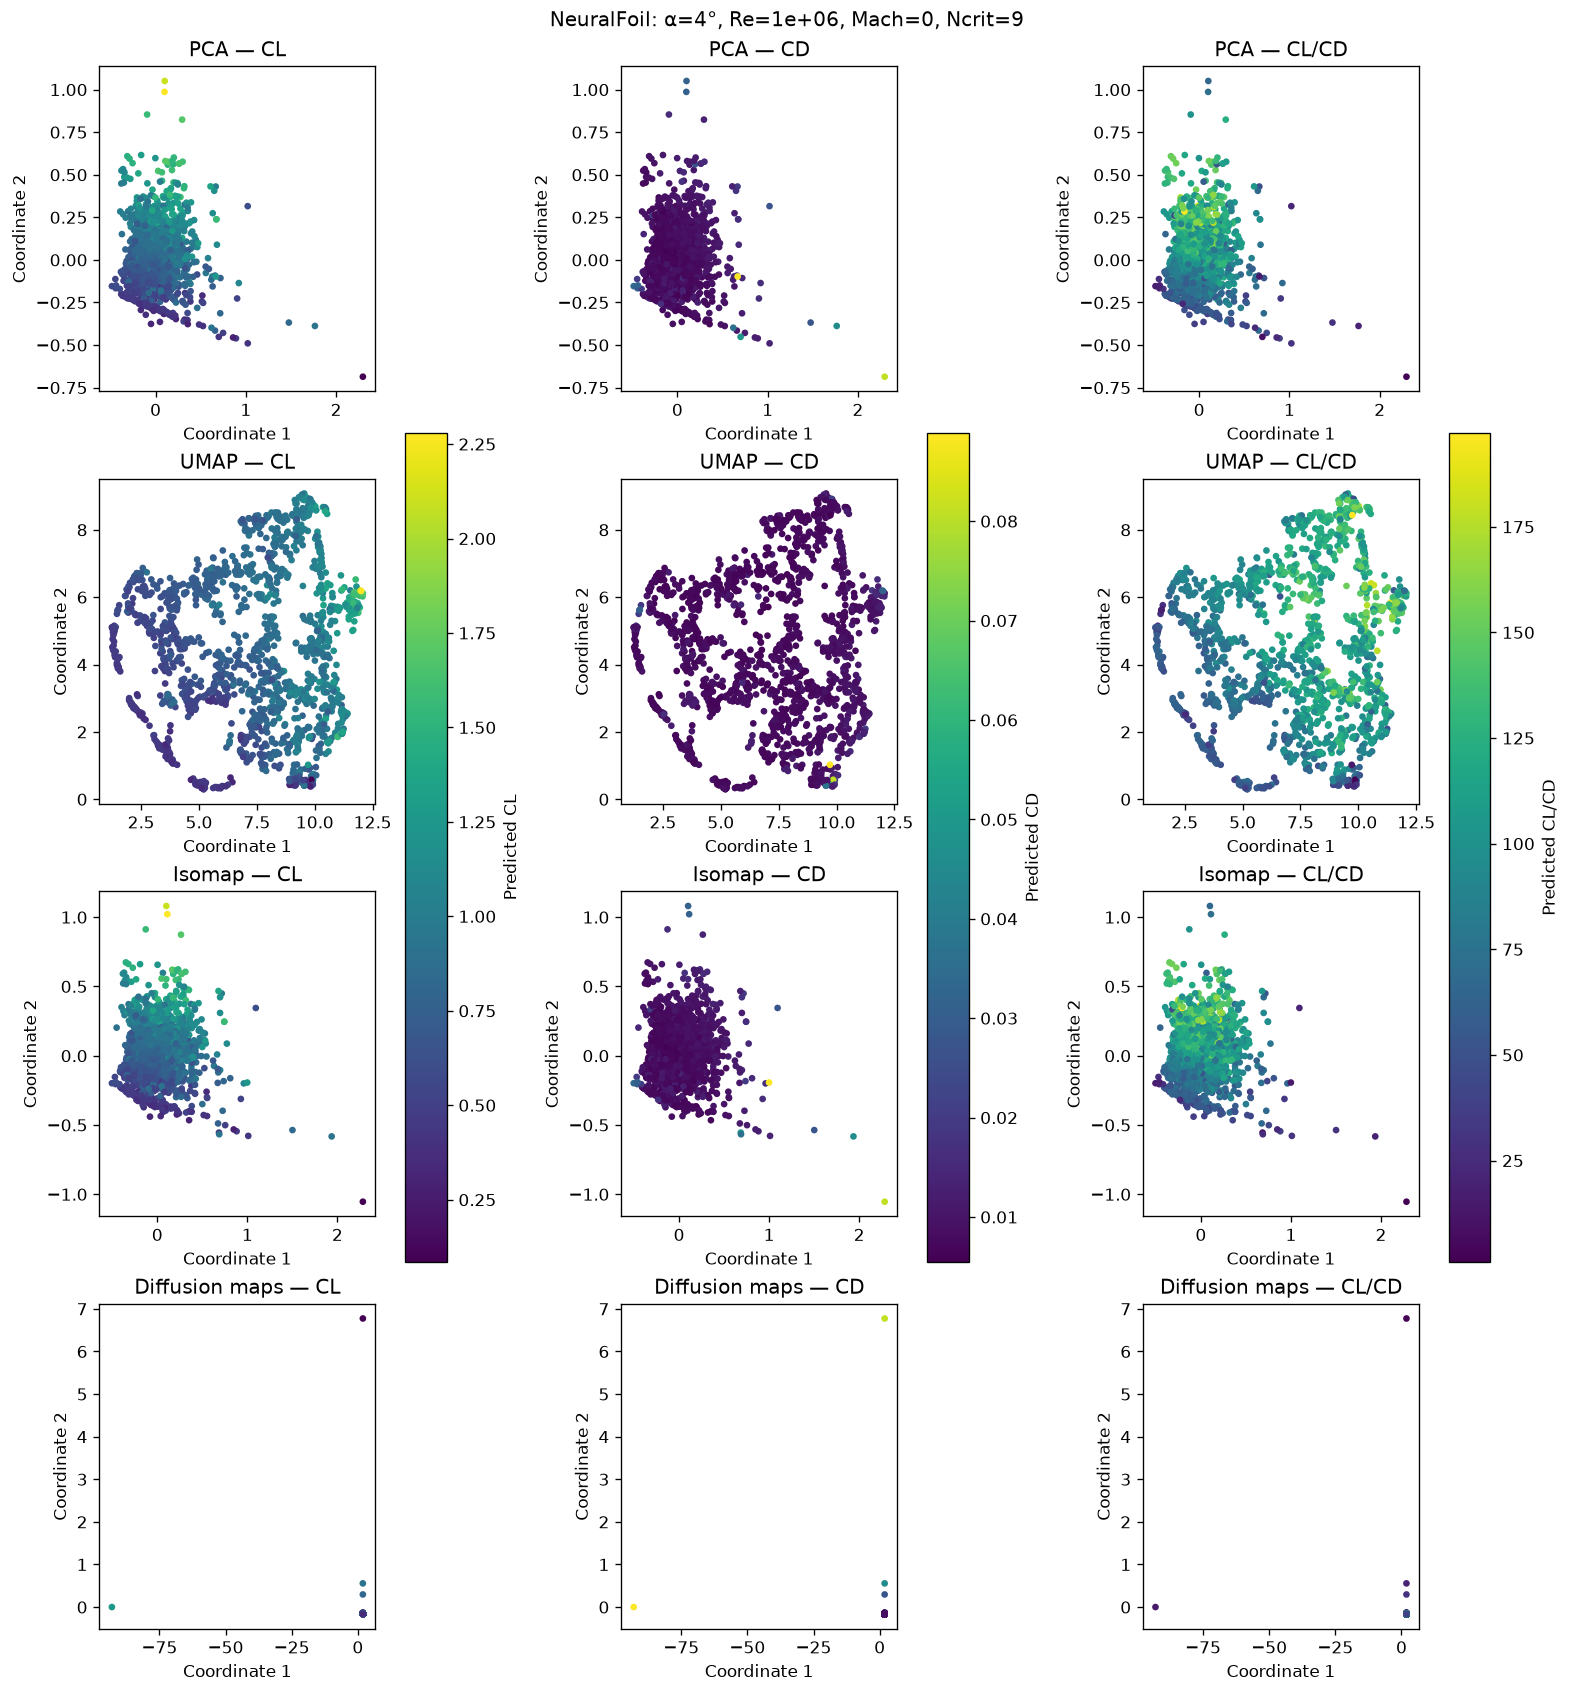

In [16]:
metrics = ["CL", "CD", "CL/CD"]
fig, axes = plt.subplots(4, 3, figsize=(13, 14), constrained_layout=True)
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgrey")
for col, metric in enumerate(metrics):
    values = performance.loc[names, metric].to_numpy()
    finite = np.isfinite(values)
    if not finite.any():
        raise ValueError(f"No finite predictions for {metric}.")
    norm = plt.Normalize(values[finite].min(), values[finite].max())
    for row, (name, embedding) in enumerate(embeddings.items()):
        ax = axes[row, col]
        points = ax.scatter(*embedding.T, c=np.ma.masked_invalid(values),
                            cmap=cmap, norm=norm, s=9, plotnonfinite=True, rasterized=True)
        ax.set(title=f"{name} — {metric}", xlabel="Coordinate 1", ylabel="Coordinate 2")
    fig.colorbar(points, ax=list(axes[:, col]), label=f"Predicted {metric}", shrink=0.6)
fig.suptitle(f"NeuralFoil: α={ALPHA:g}°, Re={REYNOLDS:g}, Mach={MACH:g}, Ncrit={N_CRIT:g}")
fig.savefig(DATA / "performance_coloured_embeddings.png", dpi=180)
plt.show()

In [12]:
metadata = {
    "source": URL,
    "archive_sha256": hashlib.sha256(archive.read_bytes()).hexdigest(),
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED, "points_per_side": POINTS_PER_SIDE, "neighbors": NEIGHBORS,
    "max_airfoils": MAX_AIRFOILS, "selected_files": len(files),
    "accepted_airfoils": len(names), "rejected_geometry": len(rejected_geometry),
    "failed_aerodynamics": int((performance["error"] != "").sum()),
    "operating_point": {"alpha_deg": ALPHA, "Re": REYNOLDS, "Mach": MACH,
                        "n_crit": N_CRIT, "xtr_upper": 1.0, "xtr_lower": 1.0},
    "neuralfoil_model_size": MODEL_SIZE,
    "umap_min_dist": 0.1, "diffusion_alpha": 0.5, "diffusion_epsilon": "median pairwise squared distance / 4",
    "diffusion_epsilon_fitted": float(models["Diffusion maps"].epsilon_fitted),
    "python": platform.python_version(),
    "versions": {package: version(package) for package in
                 ["aerosandbox", "neuralfoil", "numpy", "pandas", "scipy",
                  "matplotlib", "scikit-learn", "umap-learn", "pydiffmap"]},
}
(DATA / "run_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print(f"Saved raw coordinates, geometry, performance, embeddings, figure and metadata to {DATA}")

Saved raw coordinates, geometry, performance, embeddings, figure and metadata to /home/rraanto/programming/perso/aerodynamic-learning/data/uiuc_dimension_reduction
